# Quickstart

This page walks through a typical analysis: load a recording, look at
it, deal with blinks, filter the signal and compute the average pupil
response to an event. Every step links to a page with more details.

We start by importing the package. `u` holds the units (e.g., `u.ms`,
`u.sec`) that can be attached to times and distances. By default,
`pypillometry` logs every step; here we only show warnings.

In [1]:
import pypillometry as pp
from pypillometry import u
import matplotlib.pyplot as plt
import pandas as pd

pp.logging_set_level("WARNING")  # show only warnings, not every step

## Load data

`pypillometry` comes with a few example datasets. `rlmw_002_short` is the
first 40 seconds of a binocular recording from a reinforcement-learning
task, recorded with an Eyelink eye tracker at 500 Hz.

EyeData(rlmw_002_short, 2.0MiB):
 n                 : 20465
 sampling_rate     : 500.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'left_pupil', 'right_x', 'right_y', 'right_pupil']
 nevents           : 40
 experimental_setup: {'screen_resolution': (1280, 1024), 'physical_screen_size_mm': (300.0, 200.0), 'eye_to_screen_distance_mm': np.float64(600.0), 'camera_position': 'not set'}
 calibration       : not available
 duration_minutes  : 0.6821666666666667
 start_min         : 0.0
 end_min           : 0.6821333333333333
 params            : {}
 nblinks           : {}
 blinks            : {'left': None, 'right': None}
 glimpse           : EyeDataDict(vars=6,n=20465,shape=(20465,)): 
  left_x (float64): 655.6, 655.7, 655.0, 654.5, 655.0...
  left_y (float64): 599.9, 598.9, 597.6, 597.8, 597.8...
  left_pupil (float64): 1121.0, 1122.0, 1124.0, 1126.0, 1126.0...
  right_x (float64): 773.1, 773.8, 774.8, 776.3, 776.7...
  right_y (float64): 594.2, 593.9, 596.5, 597.4, 597.3...
  right_pupil (float64): 949.0, 951.0, 956.0, 959.0, 960.0...

 History:
 *
 └ reset_time()
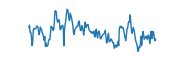
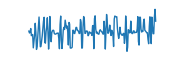
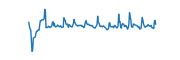
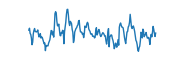
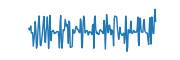
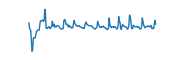

In [2]:
d = pp.get_example_data("rlmw_002_short")
d

The result is an `EyeData` object holding pupil size and gaze position
(x, y) of both eyes, the time vector, the events (triggers sent by the
experiment) and a description of the experimental setup. At the bottom,
you can see the history of all operations applied to the data.

Your own Eyelink files are read with `EyeData.from_eyelink()`:

```python
d = pp.EyeData.from_eyelink("recording.edf")
```

See [Loading data](../user_guide/loading_data.rst) for other formats.

The data is stored under keys of the form `<eye>_<variable>`:

In [3]:
print(d.eyes, d.variables)
d["left_pupil"][:10]

['left', 'right'] ['x', 'y', 'pupil']


masked_array(data=[1121.0, 1122.0, 1124.0, 1126.0, 1126.0, 1124.0, 1123.0,
                   1122.0, 1122.0, 1122.0],
             mask=[False, False, False, False, False, False, False, False,
                   False, False],
       fill_value=nan)

## Look at the data

All plotting functions are available under `d.plot`. Here we plot the
pupil size of both eyes for the first 20 seconds; the vertical lines
mark events and the shaded areas are blinks (none have been detected
yet).

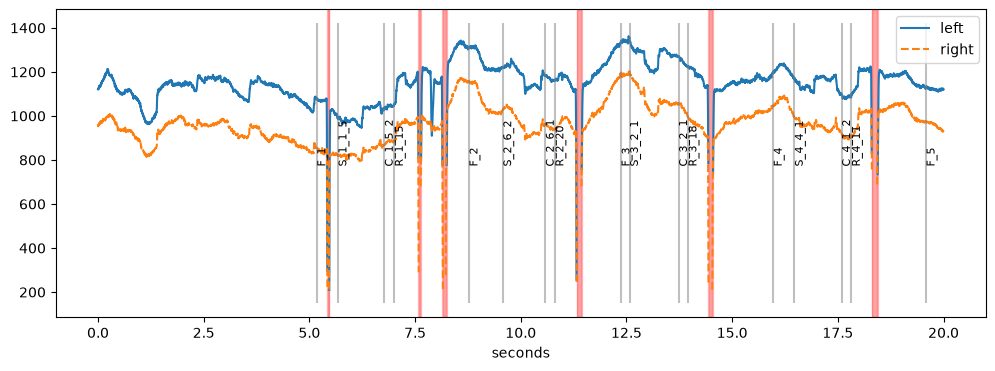

In [4]:
plt.figure(figsize=(12, 4))
d.plot.pupil_plot(plot_range=(0, 20) * u.sec)

For long recordings, the interactive viewer is faster: `pp.view(d)` opens
the data in a separate window (see [Interactive tools](../user_guide/viewer.rst)).

## Events

The events are the triggers that the experiment software sent to the eye
tracker. `get_events()` returns them as an `Events` object, which
displays as a table:

In [5]:
events = d.get_events()
events[:8]

,Onset (ms),Label
0,5177.0,F_1
1,5677.0,S_1_1_5
2,6773.0,C_1_5_2
3,7010.0,R_1_15
4,8776.0,F_2
5,9575.0,S_2_6_2
6,10581.0,C_2_6_1
7,10808.0,R_2_20


In this task, each trial has four events whose labels start with `F`,
`S`, `C` and `R`, followed by the trial number and some trial-specific
information. `filter()` selects events, e.g., all labels containing
`"S_"`:

In [6]:
events.filter("S_")

,Onset (ms),Label
0,5677.0,S_1_1_5
1,9575.0,S_2_6_2
2,12574.0,S_3_2_1
3,16473.0,S_4_4_1
4,20388.0,S_5_3_5
5,23987.0,S_6_4_5
6,27002.0,S_7_3_1
7,30601.0,S_8_6_5
8,34799.0,S_9_4_6
9,38415.0,S_10_2_5


More in the [Events tutorial](../notebooks/events.ipynb).

## Blinks

During blinks, the eye tracker loses the pupil. `pupil_blinks_detect()`
finds blinks, and `apply_mask=True` marks (masks) the affected samples
so that they are ignored in later steps. Short gaps between blinks are
merged with `blinks_merge_close()`.

Most methods return the object itself, so the steps can be chained into
a pipeline:

In [7]:
d.pupil_blinks_detect(apply_mask=True)\
 .blinks_merge_close(distance=100 * u.ms, apply_mask=True)
pd.DataFrame(d.blink_stats()).T

,n,mean,sd,min,max,total_duration,units
left,13,235.230769,260.023121,48.0,984.0,3058.0,ms
right,13,138.0,84.85644,44.0,404.0,1794.0,ms


`pupil_blinks_interpolate()` then replaces the pupil size during blinks
with a smooth interpolation (Mathôt, 2013). The interpolated samples stay
masked, so you can still tell them apart from the recorded ones.

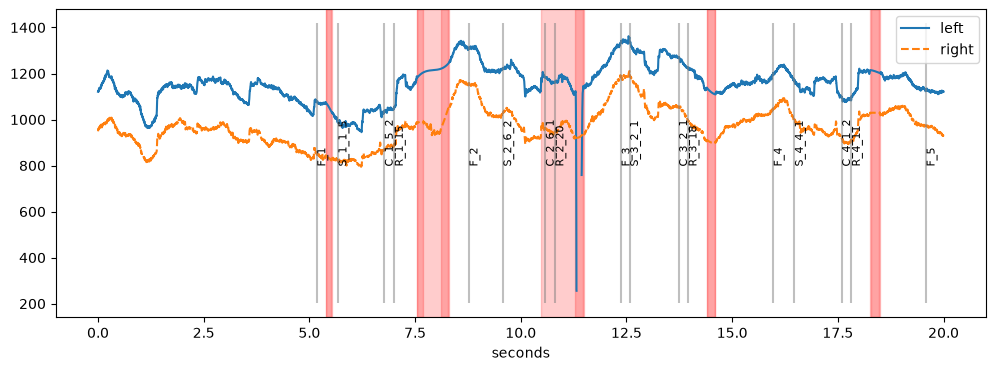

In [8]:
d.pupil_blinks_interpolate();

plt.figure(figsize=(12, 4))
d.plot.pupil_plot(plot_range=(0, 20) * u.sec)

Blink detection often needs some tuning per participant. The
[blinks tutorial](../notebooks/blinks.ipynb) shows how to check and
adjust it.

## Filtering

Pupil size changes slowly, so high-frequency noise is usually removed
with a low-pass filter (here, 4 Hz):

In [9]:
d.pupil_lowpass_filter(cutoff=4);

Every step was recorded in the object's history:

In [10]:
d.print_history()

* rlmw_002_short
└ reset_time()
 └ pupil_blinks_detect(apply_mask=True)
  └ blinks_merge_close(distance=100 ms,apply_mask=True)
   └ pupil_blinks_interpolate()
    └ pupil_lowpass_filter(cutoff=4)


Note that these operations changed `d` itself (they work *in place*).
Use `inplace=False` or `d.copy()` to keep the original; see
[Pipelines and history](../user_guide/data_model.rst#pipelines-and-history).

## Event-related pupil dilation

How does the pupil respond to the stimulus? The short example contains
only ten trials, so we switch to the full 20-minute recording of the same
participant (about 300 trials). It is downloaded once (37 MB) and then
cached. We apply the same steps as above, this time as a single pipeline:

In [11]:
d = pp.get_example_data("rlmw_002")
d.pupil_blinks_detect(apply_mask=True)\
 .blinks_merge_close(distance=100 * u.ms, apply_mask=True)\
 .pupil_blinks_interpolate()\
 .pupil_lowpass_filter(cutoff=4);

First, `get_intervals()` selects a time window around each stimulus
event, from 500 ms before until 2500 ms after its onset. The result is an
`Intervals` object (see the [Intervals tutorial](../notebooks/intervals.ipynb)):

In [12]:
intervals = d.get_intervals("S_", (-500, 2500) * u.ms)
intervals

Intervals 'S_' | 300 intervals (total duration: 900000.00 ms), 3000.00 ms +/- 0.00 ms, [3000.00 ms, 3000.00 ms] | fs=500.0Hz

`get_segments()` cuts these windows out of one variable, here the pupil
of the right eye. After subtracting the mean of the 500 ms before the
stimulus from each segment (baseline correction), `plot()` shows the
average response with its standard error:

SegmentedEyeData(stimulus):
  variable      : right_pupil
  n_segments    : 300
  n_timepoints  : 1500
  window        : (np.float64(-500.0), np.float64(2500.0))
  percent_masked: 6.50
  sampling_rate : 500.00
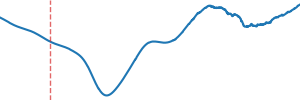

In [13]:
erpd = d.get_segments(intervals, "right_pupil", name="stimulus")\
        .baseline_correct((-500, 0))
erpd

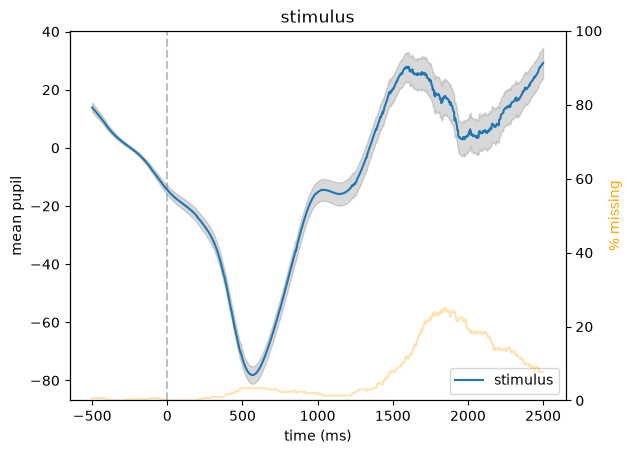

In [14]:
erpd.plot();

The pupil first constricts (a light response to the stimulus on the
screen) and then dilates. The orange line (right axis) shows the
percentage of masked samples, e.g., interpolated blinks, at each time
point.

With several participants, `pp.group_segments()` combines their
responses into a group-level curve (see the
[ERPD tutorial](../notebooks/erpds.ipynb)).

Instead of whole curves, `stat_per_event()` computes one number per
trial, e.g., the mean pupil size in the second after each stimulus. This
is useful for statistical models of trial-by-trial data:

In [15]:
means = d.stat_per_event(interval=(0, 1000) * u.ms, event_select="S_",
                         variables="pupil")
pd.DataFrame(means).round(1).head()

# ## Save the result
#
# `write_file()` saves the processed object including its history; read it
# back with `pp.EyeData.from_file()`:
#
# ```python
# d.write_file("subject01.pypil")
# d = pp.EyeData.from_file("subject01.pypil")
# ```
#
# ## Next steps
#
# - The [User guide](../user_guide/index.rst) explains the concepts used here
#   in more detail.
# - The [Tutorials](../tutorials/index.rst) contain worked examples for
#   specific tasks.
# - The [API reference](../api/index.rst) lists all classes and functions.

,left_pupil,right_pupil
0,1002.4,831.1
1,1180.9,965.9
2,1270.0,1077.6
3,1152.7,955.7
4,1098.4,912.2
